In [17]:
import itertools

import numpy as np
import pandas as pd


np.random.seed(42)

# Coded DOE factor levels
levels = [-1, 0, 1]

rows = []
run_number = 1


for temperature_code, pressure_code, time_code in itertools.product(
    levels,
    levels,
    levels
):

    # Convert coded levels into physical process settings
    temperature = 400 + 10 * temperature_code
    pressure = 50 + 5 * pressure_code
    deposition_time = 60 + 5 * time_code

    # Three replicate runs per experimental condition
    for replicate in range(1, 4):

        # Synthetic film-thickness response
        thickness = (
            100
            + 1.8 * temperature_code
            + 0.7 * pressure_code
            + 1.3 * time_code
            + 0.8 * temperature_code * time_code
            - 0.4 * pressure_code * time_code
            + np.random.normal(0, 0.25)
        )

        # Synthetic non-uniformity response
        nonuniformity = (
            1.5
            + 0.45 * temperature_code**2
            + 0.30 * pressure_code**2
            + 0.25 * time_code**2
            + 0.15 * temperature_code * pressure_code
            + np.random.normal(0, 0.08)
        )

        # Synthetic yield response
        yield_pct = (
            99.0
            - 0.7 * abs(thickness - 100)
            - 1.2 * (nonuniformity - 1.5)
            + np.random.normal(0, 0.25)
        )

        rows.append({
            "run": run_number,
            "replicate": replicate,
            "temperature_code": temperature_code,
            "pressure_code": pressure_code,
            "time_code": time_code,
            "temperature_C": temperature,
            "pressure_mTorr": pressure,
            "deposition_time_s": deposition_time,
            "film_thickness_nm": thickness,
            "nonuniformity_pct": nonuniformity,
            "yield_pct": yield_pct
        })

        run_number += 1


df = pd.DataFrame(rows)

df.to_csv(
    "data/doe_results.csv",
    index=False
)

print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nNumber of unique experimental conditions:")
print(
    df[
        [
            "temperature_C",
            "pressure_mTorr",
            "deposition_time_s"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print("\nOverall response summary:")
print(
    df[
        [
            "film_thickness_nm",
            "nonuniformity_pct",
            "yield_pct"
        ]
    ].describe()
)

   run  replicate  temperature_code  pressure_code  time_code  temperature_C  \
0    1          1                -1             -1         -1            390   
1    2          2                -1             -1         -1            390   
2    3          3                -1             -1         -1            390   
3    4          1                -1             -1          0            390   
4    5          2                -1             -1          0            390   

   pressure_mTorr  deposition_time_s  film_thickness_nm  nonuniformity_pct  \
0              45                 55          96.724179           2.638939   
1              45                 55          96.980757           2.631268   
2              45                 55          96.994803           2.711395   
3              45                 60          97.635640           2.362927   
4              45                 60          97.560491           2.246938   

   yield_pct  
0  95.502120  
1  95.470475  
2  95

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm


df = pd.read_csv("data/doe_results.csv")

print("Dataset shape:", df.shape)

print("\nResponse summary:")
print(
    df[
        [
            "film_thickness_nm",
            "nonuniformity_pct",
            "yield_pct"
        ]
    ].describe()
)

Dataset shape: (81, 11)

Response summary:
       film_thickness_nm  nonuniformity_pct  yield_pct
count          81.000000          81.000000  81.000000
mean          100.020648           2.158797  97.028456
std             2.033714           0.305404   1.071749
min            96.724179           1.427249  93.737668
25%            98.600948           1.936770  96.253826
50%            99.649537           2.164279  97.297973
75%           101.169173           2.356964  97.736672
max           104.735986           2.835173  99.299569


In [19]:
condition_summary = df.groupby(
    [
        "temperature_code",
        "pressure_code",
        "time_code",
        "temperature_C",
        "pressure_mTorr",
        "deposition_time_s"
    ]
).agg(
    mean_thickness=("film_thickness_nm", "mean"),
    mean_nonuniformity=("nonuniformity_pct", "mean"),
    mean_yield=("yield_pct", "mean")
).reset_index()

print("\nDOE condition summary:")
print(condition_summary)


DOE condition summary:
    temperature_code  pressure_code  time_code  temperature_C  pressure_mTorr  \
0                 -1             -1         -1            390              45   
1                 -1             -1          0            390              45   
2                 -1             -1          1            390              45   
3                 -1              0         -1            390              50   
4                 -1              0          0            390              50   
5                 -1              0          1            390              50   
6                 -1              1         -1            390              55   
7                 -1              1          0            390              55   
8                 -1              1          1            390              55   
9                  0             -1         -1            400              45   
10                 0             -1          0            400              45   
11  

In [20]:
factors = [
    "temperature_code",
    "pressure_code",
    "time_code"
]

for factor in factors:

    effect_summary = df.groupby(factor).agg(
        mean_thickness=("film_thickness_nm", "mean"),
        mean_nonuniformity=("nonuniformity_pct", "mean"),
        mean_yield=("yield_pct", "mean")
    )

    print(f"\nMain effect: {factor}")
    print(effect_summary)


Main effect: temperature_code
                  mean_thickness  mean_nonuniformity  mean_yield
temperature_code                                                
-1                     98.196252            2.305826   96.714242
 0                    100.010070            1.861445   97.839340
 1                    101.855621            2.309120   96.531785

Main effect: pressure_code
               mean_thickness  mean_nonuniformity  mean_yield
pressure_code                                                
-1                  99.353097            2.252752   96.719142
 0                  99.944536            1.951487   97.438963
 1                 100.764310            2.272152   96.927261

Main effect: time_code
           mean_thickness  mean_nonuniformity  mean_yield
time_code                                                
-1              98.760651            2.243466   97.092846
 0              99.970563            2.002521   97.435189
 1             101.330729            2.230404   96

In [21]:
thickness_model = smf.ols(
    formula="""
        film_thickness_nm
        ~ temperature_code
        + pressure_code
        + time_code
        + temperature_code:pressure_code
        + temperature_code:time_code
        + pressure_code:time_code
    """,
    data=df
).fit()

print("\n--- THICKNESS REGRESSION MODEL ---")
print(thickness_model.summary())


--- THICKNESS REGRESSION MODEL ---
                            OLS Regression Results                            
Dep. Variable:      film_thickness_nm   R-squared:                       0.991
Model:                            OLS   Adj. R-squared:                  0.991
Method:                 Least Squares   F-statistic:                     1403.
Date:                Sun, 27 Sep 2026   Prob (F-statistic):           4.49e-74
Time:                        23:58:06   Log-Likelihood:                 20.150
No. Observations:                  81   AIC:                            -26.30
Df Residuals:                      74   BIC:                            -9.539
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

In [22]:
thickness_anova = anova_lm(
    thickness_model,
    typ=2
)

print("\n--- THICKNESS ANOVA ---")
print(thickness_anova)


--- THICKNESS ANOVA ---
                                    sum_sq    df            F        PR(>F)
temperature_code                180.778255   1.0  4639.170642  1.652681e-68
pressure_code                    26.885568   1.0   689.943246  2.990083e-39
time_code                        89.171504   1.0  2288.338400  2.091698e-57
temperature_code:pressure_code    0.002658   1.0     0.068218  7.946753e-01
temperature_code:time_code       26.595064   1.0   682.488280  4.300165e-39
pressure_code:time_code           4.562825   1.0   117.092199  6.672021e-17
Residual                          2.883617  74.0          NaN           NaN


In [23]:
nonuniformity_model = smf.ols(
    formula="""
        nonuniformity_pct
        ~ temperature_code
        + pressure_code
        + time_code
        + I(temperature_code ** 2)
        + I(pressure_code ** 2)
        + I(time_code ** 2)
        + temperature_code:pressure_code
        + temperature_code:time_code
        + pressure_code:time_code
    """,
    data=df
).fit()

print("\n--- NON-UNIFORMITY MODEL ---")
print(nonuniformity_model.summary())

nonuniformity_anova = anova_lm(
    nonuniformity_model,
    typ=2
)

print("\n--- NON-UNIFORMITY ANOVA ---")
print(nonuniformity_anova)


--- NON-UNIFORMITY MODEL ---
                            OLS Regression Results                            
Dep. Variable:      nonuniformity_pct   R-squared:                       0.944
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     133.6
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           7.36e-41
Time:                        00:01:02   Log-Likelihood:                 98.545
No. Observations:                  81   AIC:                            -177.1
Df Residuals:                      71   BIC:                            -153.1
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------

In [24]:
condition_summary["thickness_error"] = abs(
    condition_summary["mean_thickness"] - 100
)

best_yield_conditions = condition_summary.sort_values(
    "mean_yield",
    ascending=False
)

print("\n--- HIGHEST-YIELD CONDITIONS ---")

print(
    best_yield_conditions[
        [
            "temperature_C",
            "pressure_mTorr",
            "deposition_time_s",
            "mean_thickness",
            "mean_nonuniformity",
            "mean_yield"
        ]
    ].head()
)


--- HIGHEST-YIELD CONDITIONS ---
    temperature_C  pressure_mTorr  deposition_time_s  mean_thickness  \
13            400              50                 60       99.851709   
15            400              55                 55      100.105883   
21            410              50                 55       99.623714   
16            400              55                 60      100.632493   
10            400              45                 60       99.305461   

    mean_nonuniformity  mean_yield  
13            1.521874   99.139758  
15            1.953424   98.389276  
21            2.131304   98.077644  
16            1.844006   98.009449  
10            1.822336   97.946982  


In [25]:
feasible_conditions = condition_summary[
    (condition_summary["thickness_error"] <= 0.5)
    & (condition_summary["mean_nonuniformity"] <= 1.8)
].copy()

feasible_conditions = feasible_conditions.sort_values(
    "mean_yield",
    ascending=False
)

print("\n--- FEASIBLE PROCESS WINDOW ---")

print(
    feasible_conditions[
        [
            "temperature_C",
            "pressure_mTorr",
            "deposition_time_s",
            "mean_thickness",
            "mean_nonuniformity",
            "mean_yield"
        ]
    ]
)


--- FEASIBLE PROCESS WINDOW ---
    temperature_C  pressure_mTorr  deposition_time_s  mean_thickness  \
13            400              50                 60       99.851709   

    mean_nonuniformity  mean_yield  
13            1.521874   99.139758  


In [26]:
best_condition = feasible_conditions.iloc[0]

print("\n--- SELECTED OPERATING CONDITION ---")

print(
    f"Temperature: "
    f"{best_condition['temperature_C']:.0f} C"
)

print(
    f"Pressure: "
    f"{best_condition['pressure_mTorr']:.0f} mTorr"
)

print(
    f"Deposition time: "
    f"{best_condition['deposition_time_s']:.0f} s"
)

print(
    f"Mean thickness: "
    f"{best_condition['mean_thickness']:.2f} nm"
)

print(
    f"Mean non-uniformity: "
    f"{best_condition['mean_nonuniformity']:.2f}%"
)

print(
    f"Mean yield: "
    f"{best_condition['mean_yield']:.2f}%"
)


--- SELECTED OPERATING CONDITION ---
Temperature: 400 C
Pressure: 50 mTorr
Deposition time: 60 s
Mean thickness: 99.85 nm
Mean non-uniformity: 1.52%
Mean yield: 99.14%


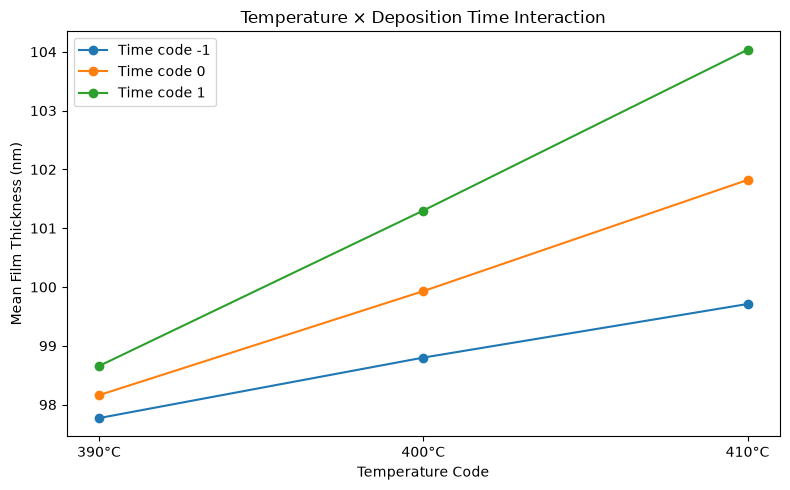

In [27]:
interaction_summary = df.groupby(
    ["temperature_code", "time_code"]
)["film_thickness_nm"].mean().reset_index()

plt.figure(figsize=(8, 5))

for time_code in [-1, 0, 1]:

    subset = interaction_summary[
        interaction_summary["time_code"] == time_code
    ]

    plt.plot(
        subset["temperature_code"],
        subset["film_thickness_nm"],
        marker="o",
        label=f"Time code {time_code}"
    )

plt.xlabel("Temperature Code")
plt.ylabel("Mean Film Thickness (nm)")
plt.title("Temperature × Deposition Time Interaction")

plt.xticks(
    [-1, 0, 1],
    ["390°C", "400°C", "410°C"]
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/temperature_time_interaction.png",
    dpi=300
)

plt.show()

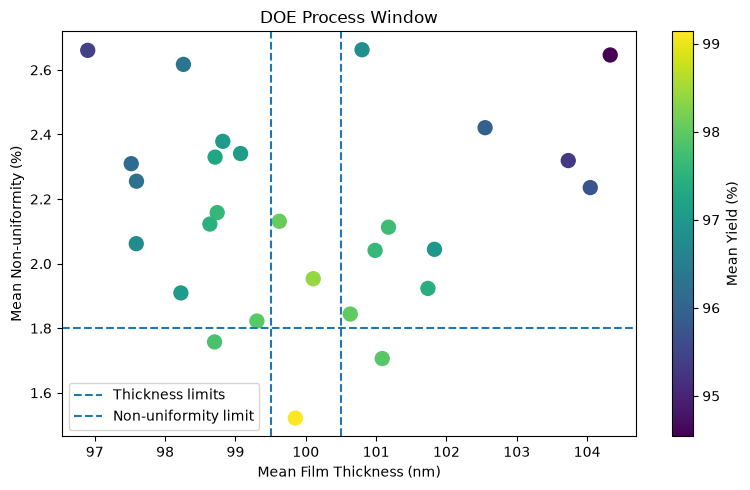

In [28]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    condition_summary["mean_thickness"],
    condition_summary["mean_nonuniformity"],
    c=condition_summary["mean_yield"],
    s=100
)

plt.axvline(
    99.5,
    linestyle="--",
    label="Thickness limits"
)

plt.axvline(
    100.5,
    linestyle="--"
)

plt.axhline(
    1.8,
    linestyle="--",
    label="Non-uniformity limit"
)

plt.xlabel("Mean Film Thickness (nm)")
plt.ylabel("Mean Non-uniformity (%)")
plt.title("DOE Process Window")

plt.colorbar(
    scatter,
    label="Mean Yield (%)"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/process_window.png",
    dpi=300
)

plt.show()